# 1. DATA LOADING AND CLEANING

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option("display.max_columns", None)

In [3]:
delhi = pd.read_csv("/content/csv_28.704059_77.10249_fixed_26_180_PT15M.csv")
raipur = pd.read_csv("/content/csv_21.251384_81.629641_fixed_20_180_PT15M.csv")
jaisalmer = pd.read_csv("/content/csv_26.90898_70.91464_fixed_25_180_PT15M.csv")

In [4]:
delhi.head()

,air_temp,cloud_opacity,dhi,dni,ghi,gti,relative_humidity,wind_speed_10m,period_end,period
0,9.7,0.0,0,0,0,0,94.2,1.7,2025-01-01T00:15:00+05:00,PT15M
1,9.5,0.0,0,0,0,0,94.4,1.7,2025-01-01T00:30:00+05:00,PT15M
2,9.4,0.0,0,0,0,0,94.5,1.7,2025-01-01T00:45:00+05:00,PT15M
3,9.2,0.0,0,0,0,0,94.7,1.7,2025-01-01T01:00:00+05:00,PT15M
4,9.1,0.0,0,0,0,0,94.7,1.7,2025-01-01T01:15:00+05:00,PT15M


In [5]:
print("Delhi:", delhi.shape)
print("Raipur:", raipur.shape)
print("Jaisalmer:", jaisalmer.shape)

Delhi: (34944, 10)
Raipur: (34944, 10)
Jaisalmer: (34944, 10)


In [6]:
delhi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34944 entries, 0 to 34943
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   air_temp           34944 non-null  float64
 1   cloud_opacity      34944 non-null  float64
 2   dhi                34944 non-null  int64  
 3   dni                34944 non-null  int64  
 4   ghi                34944 non-null  int64  
 5   gti                34944 non-null  int64  
 6   relative_humidity  34944 non-null  float64
 7   wind_speed_10m     34944 non-null  float64
 8   period_end         34944 non-null  object 
 9   period             34944 non-null  object 
dtypes: float64(4), int64(4), object(2)
memory usage: 2.7+ MB


In [7]:
delhi.columns

Index(['air_temp', 'cloud_opacity', 'dhi', 'dni', 'ghi', 'gti',
       'relative_humidity', 'wind_speed_10m', 'period_end', 'period'],
      dtype='object')

In [8]:
###first transformation, adding a new column for the city in the dataset.

delhi["location"] = "Delhi"
raipur["location"] = "Raipur"
jaisalmer["location"] = "Jaisalmer"

In [9]:
delhi.head()

,air_temp,cloud_opacity,dhi,dni,ghi,gti,relative_humidity,wind_speed_10m,period_end,period,location
0,9.7,0.0,0,0,0,0,94.2,1.7,2025-01-01T00:15:00+05:00,PT15M,Delhi
1,9.5,0.0,0,0,0,0,94.4,1.7,2025-01-01T00:30:00+05:00,PT15M,Delhi
2,9.4,0.0,0,0,0,0,94.5,1.7,2025-01-01T00:45:00+05:00,PT15M,Delhi
3,9.2,0.0,0,0,0,0,94.7,1.7,2025-01-01T01:00:00+05:00,PT15M,Delhi
4,9.1,0.0,0,0,0,0,94.7,1.7,2025-01-01T01:15:00+05:00,PT15M,Delhi


In [10]:
df = pd.concat(
    [delhi, raipur, jaisalmer],
    ignore_index=True
)

In [11]:
df.shape

(104832, 11)

In [12]:
df["location"].value_counts()

,count
location,
Delhi,34944
Raipur,34944
Jaisalmer,34944


In [13]:
df.head()

,air_temp,cloud_opacity,dhi,dni,ghi,gti,relative_humidity,wind_speed_10m,period_end,period,location
0,9.7,0.0,0,0,0,0,94.2,1.7,2025-01-01T00:15:00+05:00,PT15M,Delhi
1,9.5,0.0,0,0,0,0,94.4,1.7,2025-01-01T00:30:00+05:00,PT15M,Delhi
2,9.4,0.0,0,0,0,0,94.5,1.7,2025-01-01T00:45:00+05:00,PT15M,Delhi
3,9.2,0.0,0,0,0,0,94.7,1.7,2025-01-01T01:00:00+05:00,PT15M,Delhi
4,9.1,0.0,0,0,0,0,94.7,1.7,2025-01-01T01:15:00+05:00,PT15M,Delhi


In [14]:
df.tail()

,air_temp,cloud_opacity,dhi,dni,ghi,gti,relative_humidity,wind_speed_10m,period_end,period,location
104827,17.1,12.7,0,0,0,0,52.5,3.6,2025-12-30T23:00:00+04:00,PT15M,Jaisalmer
104828,16.9,12.7,0,0,0,0,53.2,3.6,2025-12-30T23:15:00+04:00,PT15M,Jaisalmer
104829,16.5,12.2,0,0,0,0,54.5,3.6,2025-12-30T23:30:00+04:00,PT15M,Jaisalmer
104830,16.1,12.2,0,0,0,0,55.9,3.5,2025-12-30T23:45:00+04:00,PT15M,Jaisalmer
104831,15.7,12.7,0,0,0,0,57.4,3.5,2025-12-31T00:00:00+04:00,PT15M,Jaisalmer


In [15]:
df.sample(5)

,air_temp,cloud_opacity,dhi,dni,ghi,gti,relative_humidity,wind_speed_10m,period_end,period,location
101252,24.9,0.0,0,0,0,0,22.8,3.1,2025-11-23T17:15:00+04:00,PT15M,Jaisalmer
58233,30.7,61.5,250,0,250,244,73.7,1.7,2025-08-31T14:30:00+05:00,PT15M,Raipur
43541,38.8,0.0,289,598,802,831,15.3,0.6,2025-03-31T13:30:00+05:00,PT15M,Raipur
50366,35.7,20.5,262,0,262,255,48.2,4.3,2025-06-10T15:45:00+05:00,PT15M,Raipur
51953,25.9,91.8,0,0,0,0,86.9,3.8,2025-06-27T04:30:00+05:00,PT15M,Raipur


In [16]:
df.isna().sum()

,0
air_temp,0
cloud_opacity,0
dhi,0
dni,0
ghi,0
gti,0
relative_humidity,0
wind_speed_10m,0
period_end,0
period,0


In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df.describe()

,air_temp,cloud_opacity,dhi,dni,ghi,gti,relative_humidity,wind_speed_10m
count,104832.000000,104832.000000,104832.000000,104832.000000,104832.000000,104832.000000,104832.000000,104832.000000
mean,26.274579,23.687528,100.537145,159.507717,206.731160,224.250735,61.459852,2.869108
std,7.383710,28.945925,133.338826,258.573892,286.450666,313.893666,22.814009,1.685937
min,6.500000,0.000000,0.000000,0.000000,0.000000,0.000000,2.400000,0.000000
25%,21.800000,0.000000,0.000000,0.000000,0.000000,0.000000,43.500000,1.700000
50%,27.300000,10.200000,1.000000,0.000000,1.000000,1.000000,63.400000,2.450000
75%,31.100000,40.900000,187.000000,295.000000,399.000000,424.000000,81.400000,3.700000
max,46.000000,97.000000,626.000000,997.000000,1036.000000,1126.000000,100.000000,11.900000


In [19]:
df["period_end"].head()

,period_end
0,2025-01-01T00:15:00+05:00
1,2025-01-01T00:30:00+05:00
2,2025-01-01T00:45:00+05:00
3,2025-01-01T01:00:00+05:00
4,2025-01-01T01:15:00+05:00


In [20]:
df["period_end"].dtype

dtype('O')

In [21]:
print(df["period_end"].head(10).tolist())

['2025-01-01T00:15:00+05:00', '2025-01-01T00:30:00+05:00', '2025-01-01T00:45:00+05:00', '2025-01-01T01:00:00+05:00', '2025-01-01T01:15:00+05:00', '2025-01-01T01:30:00+05:00', '2025-01-01T01:45:00+05:00', '2025-01-01T02:00:00+05:00', '2025-01-01T02:15:00+05:00', '2025-01-01T02:30:00+05:00']


In [22]:
print(df.groupby("location")["period_end"].agg(["min", "max"]))

                                 min                        max
location                                                       
Delhi      2025-01-01T00:15:00+05:00  2025-12-31T00:00:00+05:00
Jaisalmer  2025-01-01T00:15:00+04:00  2025-12-31T00:00:00+04:00
Raipur     2025-01-01T00:15:00+05:00  2025-12-31T00:00:00+05:00


In [23]:
# Preserve the original timestamps
df["period_end_original"] = df["period_end"]

# Parse timestamps and convert to IST in a separate column
df["period_end_ist"] = (
    pd.to_datetime(df["period_end"], utc=True)
      .dt.tz_convert("Asia/Kolkata")
)

# Compare the two representations
print(df[["period_end_original", "period_end_ist"]].head())

         period_end_original            period_end_ist
0  2025-01-01T00:15:00+05:00 2025-01-01 00:45:00+05:30
1  2025-01-01T00:30:00+05:00 2025-01-01 01:00:00+05:30
2  2025-01-01T00:45:00+05:00 2025-01-01 01:15:00+05:30
3  2025-01-01T01:00:00+05:00 2025-01-01 01:30:00+05:30
4  2025-01-01T01:15:00+05:00 2025-01-01 01:45:00+05:30


In [24]:
for location, group in df.groupby("location"):
    timestamps = (
        group["period_end_ist"]
        .sort_values()
    )

    print(f"\n{location}")
    print("First:", timestamps.min())
    print("Last:", timestamps.max())
    print("Rows:", len(timestamps))
    print("Unique timestamps:", timestamps.nunique())
    print("Duplicate timestamps:", timestamps.duplicated().sum())
    print("\nMost common intervals:")
    print(timestamps.diff().value_counts().head())


Delhi
First: 2025-01-01 00:45:00+05:30
Last: 2025-12-31 00:30:00+05:30
Rows: 34944
Unique timestamps: 34944
Duplicate timestamps: 0

Most common intervals:
period_end_ist
0 days 00:15:00    34943
Name: count, dtype: int64

Jaisalmer
First: 2025-01-01 01:45:00+05:30
Last: 2025-12-31 01:30:00+05:30
Rows: 34944
Unique timestamps: 34944
Duplicate timestamps: 0

Most common intervals:
period_end_ist
0 days 00:15:00    34943
Name: count, dtype: int64

Raipur
First: 2025-01-01 00:45:00+05:30
Last: 2025-12-31 00:30:00+05:30
Rows: 34944
Unique timestamps: 34944
Duplicate timestamps: 0

Most common intervals:
period_end_ist
0 days 00:15:00    34943
Name: count, dtype: int64


In [25]:
df = df.sort_values(
    ["location", "period_end_ist"]
).reset_index(drop=True)

# 2. EDA

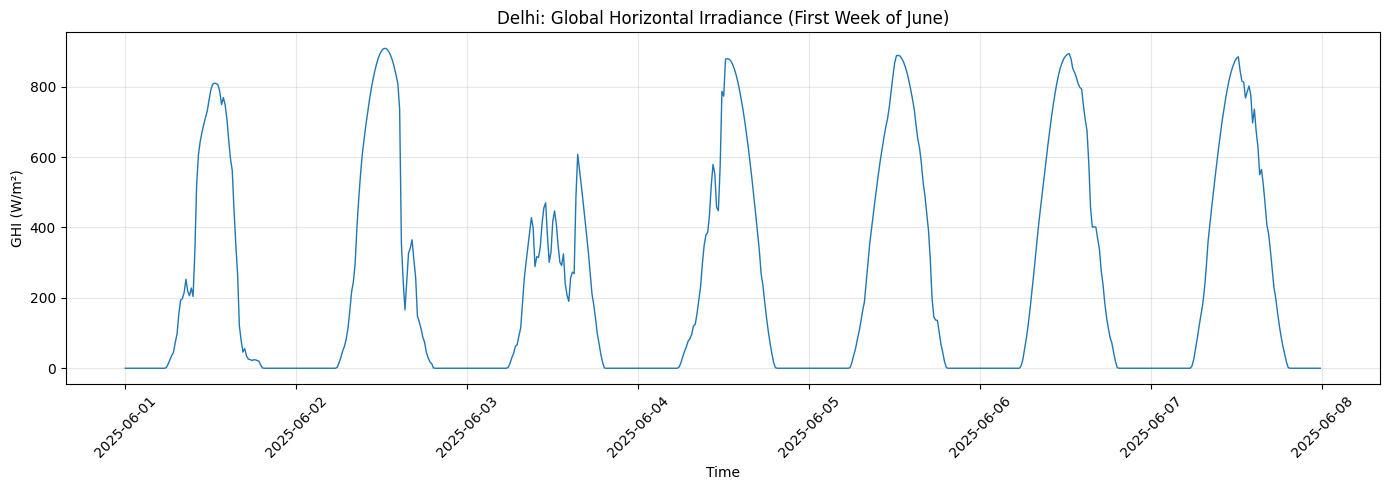

In [26]:
delhi_week = df[
    (df["location"] == "Delhi") &
    (df["period_end_ist"] >= "2025-06-01") &
    (df["period_end_ist"] < "2025-06-08")
]

plt.figure(figsize=(14, 5))

plt.plot(
    delhi_week["period_end_ist"],
    delhi_week["ghi"],
    linewidth=1
)

plt.title("Delhi: Global Horizontal Irradiance (First Week of June)")
plt.xlabel("Time")
plt.ylabel("GHI (W/m²)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
delhi_june = df[
    (df["location"] == "Delhi") &
    (df["period_end_ist"] >= "2025-06-01") &
    (df["period_end_ist"] < "2025-06-08")
].copy()

delhi_june["date"] = delhi_june["period_end_ist"].dt.date

daily_stats = delhi_june.groupby("date").agg(
    mean_ghi=("ghi", "mean"),
    max_ghi=("ghi", "max"),
    mean_gti=("gti", "mean"),
    max_gti=("gti", "max"),
    mean_temp=("air_temp", "mean"),
    mean_cloud=("cloud_opacity", "mean")
).round(2)

daily_stats

,mean_ghi,max_ghi,mean_gti,max_gti,mean_temp,mean_cloud
date,,,,,,
2025-06-01,197.93,810,189.22,779,30.83,49.76
2025-06-02,250.25,909,237.07,872,30.18,44.65
2025-06-03,157.61,608,147.18,558,28.90,44.12
2025-06-04,236.61,880,222.00,844,27.76,34.25
2025-06-05,263.93,889,248.05,852,29.50,29.79
2025-06-06,277.62,894,258.94,855,31.82,20.44
2025-06-07,273.51,885,254.83,846,33.85,17.48


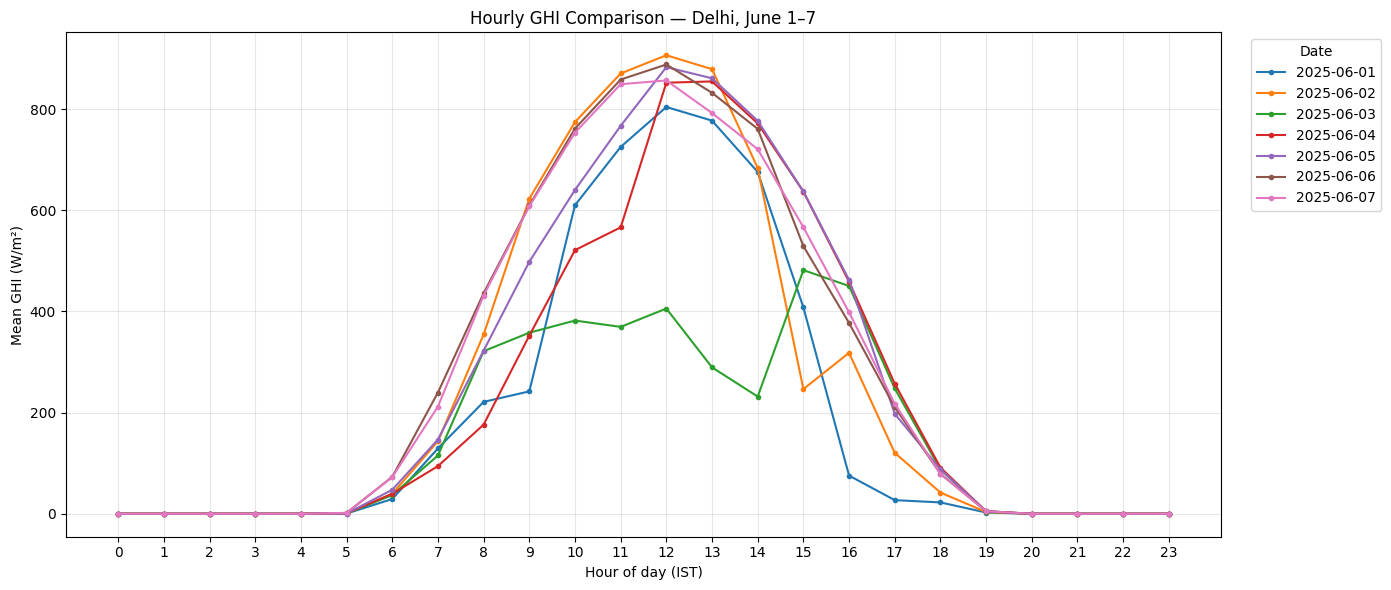

In [28]:
delhi_june["hour"] = (
    delhi_june["period_end_ist"].dt.hour
)

hourly_ghi = delhi_june.pivot_table(
    index="hour",
    columns=delhi_june["period_end_ist"].dt.date,
    values="ghi",
    aggfunc="mean"
)

hourly_ghi.plot(
    figsize=(14, 6),
    marker=".",
    linewidth=1.5
)

plt.title("Hourly GHI Comparison — Delhi, June 1–7")
plt.xlabel("Hour of day (IST)")
plt.ylabel("Mean GHI (W/m²)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.legend(title="Date", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

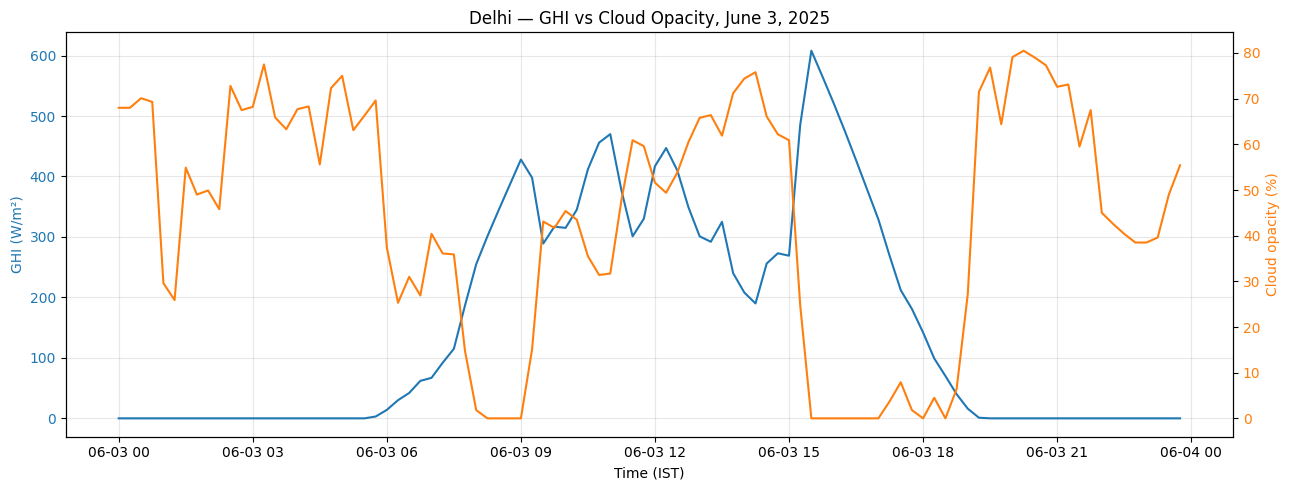

In [29]:
june3 = delhi_june[
    delhi_june["date"] == pd.to_datetime("2025-06-03").date()
].copy()

fig, ax1 = plt.subplots(figsize=(13, 5))

ax1.plot(
    june3["period_end_ist"],
    june3["ghi"],
    color="tab:blue",
    label="GHI (W/m²)"
)
ax1.set_xlabel("Time (IST)")
ax1.set_ylabel("GHI (W/m²)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(
    june3["period_end_ist"],
    june3["cloud_opacity"],
    color="tab:orange",
    label="Cloud opacity (%)"
)
ax2.set_ylabel("Cloud opacity (%)", color="tab:orange")
ax2.tick_params(axis="y", labelcolor="tab:orange")

plt.title("Delhi — GHI vs Cloud Opacity, June 3, 2025")
fig.tight_layout()
plt.show()

In [30]:
daylight = june3[june3["ghi"] > 50].copy()

print(
    daylight[["ghi", "cloud_opacity", "air_temp"]]
    .corr()
    .round(3)
)

                 ghi  cloud_opacity  air_temp
ghi            1.000         -0.153     0.222
cloud_opacity -0.153          1.000     0.148
air_temp       0.222          0.148     1.000


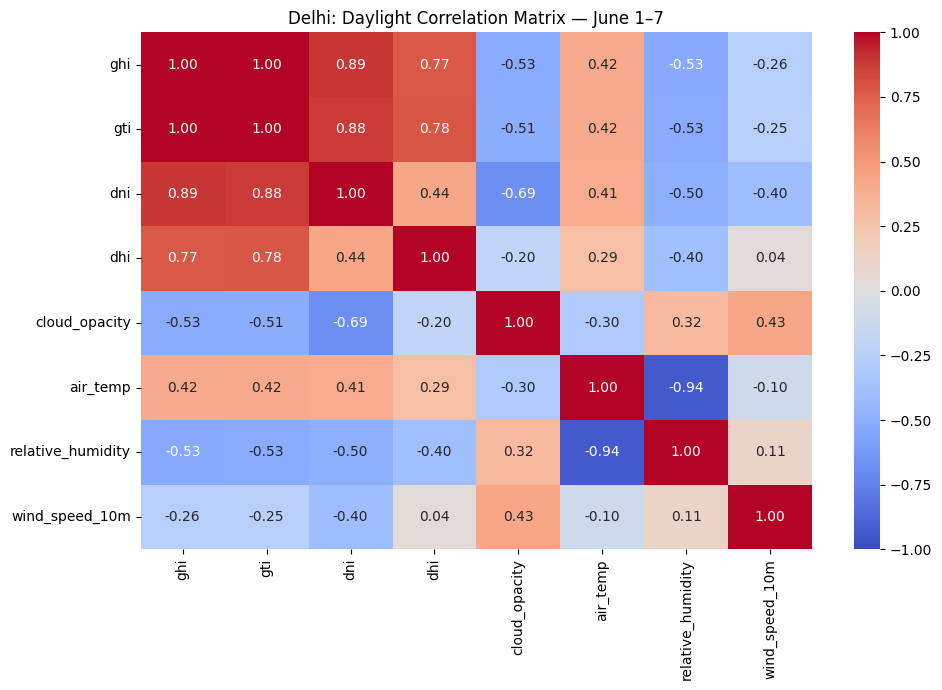

In [31]:
delhi_june_daylight = delhi_june[
    delhi_june["ghi"] > 50
].copy()

corr = delhi_june_daylight[
    ["ghi", "gti", "dni", "dhi",
     "cloud_opacity", "air_temp",
     "relative_humidity", "wind_speed_10m"]
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Delhi: Daylight Correlation Matrix — June 1–7")
plt.tight_layout()
plt.show()

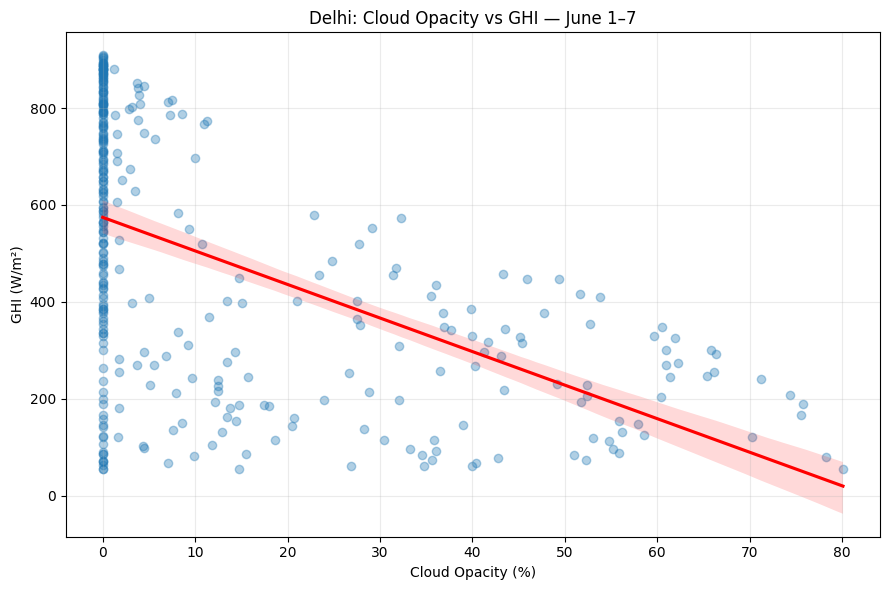

In [32]:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=delhi_june_daylight,
    x="cloud_opacity",
    y="ghi",
    scatter_kws={"alpha": 0.35},
    line_kws={"color": "red"}
)

plt.title("Delhi: Cloud Opacity vs GHI — June 1–7")
plt.xlabel("Cloud Opacity (%)")
plt.ylabel("GHI (W/m²)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [33]:
from scipy.stats import linregress

result = linregress(
    delhi_june_daylight["cloud_opacity"],
    delhi_june_daylight["ghi"]
)

print(f"Slope: {result.slope:.2f}")
print(f"Intercept: {result.intercept:.2f}")
print(f"Correlation (r): {result.rvalue:.3f}")
print(f"R-squared: {result.rvalue**2:.3f}")
print(f"P-value: {result.pvalue:.4g}")

Slope: -6.93
Intercept: 574.54
Correlation (r): -0.530
R-squared: 0.281
P-value: 2.684e-25


In [34]:

# Step 1: Check timestamp coverage by location

df["period_end_ist"] = pd.to_datetime(
    df["period_end_ist"], errors="coerce"
)

coverage = df.groupby("location").agg(
    observations=("period_end_ist", "count"),
    first_timestamp=("period_end_ist", "min"),
    last_timestamp=("period_end_ist", "max"),
    unique_timestamps=("period_end_ist", "nunique")
)

print(coverage)


           observations           first_timestamp            last_timestamp  \
location                                                                      
Delhi             34944 2025-01-01 00:45:00+05:30 2025-12-31 00:30:00+05:30   
Jaisalmer         34944 2025-01-01 01:45:00+05:30 2025-12-31 01:30:00+05:30   
Raipur            34944 2025-01-01 00:45:00+05:30 2025-12-31 00:30:00+05:30   

           unique_timestamps  
location                      
Delhi                  34944  
Jaisalmer              34944  
Raipur                 34944  


In [35]:

# Step 2: Count observations per local calendar day

df["date_ist"] = df["period_end_ist"].dt.date

daily_counts = (
    df.groupby(["location", "date_ist"])
      .size()
      .rename("observations")
      .reset_index()
)

print(daily_counts.groupby("location")["observations"].describe())

# Inspect days that do not have 96 observations
print(
    daily_counts[daily_counts["observations"] != 96]
    .head(20)
)


           count       mean       std  min   25%   50%   75%   max
location                                                          
Delhi      365.0  95.736986  4.869943  3.0  96.0  96.0  96.0  96.0
Jaisalmer  365.0  95.736986  4.671856  7.0  96.0  96.0  96.0  96.0
Raipur     365.0  95.736986  4.869943  3.0  96.0  96.0  96.0  96.0
       location    date_ist  observations
0         Delhi  2025-01-01            93
364       Delhi  2025-12-31             3
365   Jaisalmer  2025-01-01            89
729   Jaisalmer  2025-12-31             7
730      Raipur  2025-01-01            93
1094     Raipur  2025-12-31             3


In [36]:

# Compare original timestamps with the converted timestamps

print(
    df[[
        "location",
        "period_end_original",
        "period_end",
        "period_end_ist"
    ]]
    .groupby("location")
    .head(3)
    .to_string(index=False)
)


 location       period_end_original                period_end            period_end_ist
    Delhi 2025-01-01T00:15:00+05:00 2025-01-01T00:15:00+05:00 2025-01-01 00:45:00+05:30
    Delhi 2025-01-01T00:30:00+05:00 2025-01-01T00:30:00+05:00 2025-01-01 01:00:00+05:30
    Delhi 2025-01-01T00:45:00+05:00 2025-01-01T00:45:00+05:00 2025-01-01 01:15:00+05:30
Jaisalmer 2025-01-01T00:15:00+04:00 2025-01-01T00:15:00+04:00 2025-01-01 01:45:00+05:30
Jaisalmer 2025-01-01T00:30:00+04:00 2025-01-01T00:30:00+04:00 2025-01-01 02:00:00+05:30
Jaisalmer 2025-01-01T00:45:00+04:00 2025-01-01T00:45:00+04:00 2025-01-01 02:15:00+05:30
   Raipur 2025-01-01T00:15:00+05:00 2025-01-01T00:15:00+05:00 2025-01-01 00:45:00+05:30
   Raipur 2025-01-01T00:30:00+05:00 2025-01-01T00:30:00+05:00 2025-01-01 01:00:00+05:30
   Raipur 2025-01-01T00:45:00+05:00 2025-01-01T00:45:00+05:00 2025-01-01 01:15:00+05:30


In [37]:

# Extract the date exactly as written in the source timestamp
df["source_date"] = df["period_end_original"].str[:10]

source_daily_counts = (
    df.groupby(["location", "source_date"])
      .size()
      .rename("observations")
      .reset_index()
)

# How many source dates does each city contain?
print(
    source_daily_counts.groupby("location").agg(
        source_dates=("source_date", "nunique"),
        total_observations=("observations", "sum"),
        min_per_day=("observations", "min"),
        max_per_day=("observations", "max")
    )
)

# Inspect the beginning and end of each city's source coverage
for city in df["location"].unique():
    city_days = source_daily_counts[
        source_daily_counts["location"] == city
    ]

    print(f"\n{city}")
    print("First dates:")
    print(city_days.head(3).to_string(index=False))
    print("Last dates:")
    print(city_days.tail(3).to_string(index=False))


           source_dates  total_observations  min_per_day  max_per_day
location                                                             
Delhi               365               34944            1           96
Jaisalmer           365               34944            1           96
Raipur              365               34944            1           96

Delhi
First dates:
location source_date  observations
   Delhi  2025-01-01            95
   Delhi  2025-01-02            96
   Delhi  2025-01-03            96
Last dates:
location source_date  observations
   Delhi  2025-12-29            96
   Delhi  2025-12-30            96
   Delhi  2025-12-31             1

Jaisalmer
First dates:
 location source_date  observations
Jaisalmer  2025-01-01            95
Jaisalmer  2025-01-02            96
Jaisalmer  2025-01-03            96
Last dates:
 location source_date  observations
Jaisalmer  2025-12-29            96
Jaisalmer  2025-12-30            96
Jaisalmer  2025-12-31             1

Raipur
First 

In [38]:

print("Columns available:")
print(df.columns.tolist())


Columns available:
['air_temp', 'cloud_opacity', 'dhi', 'dni', 'ghi', 'gti', 'relative_humidity', 'wind_speed_10m', 'period_end', 'period', 'location', 'period_end_original', 'period_end_ist', 'date_ist', 'source_date']


# 3. ML

In [39]:

import numpy as np
import pandas as pd

# Work on a separate copy; preserve our original df
ml_df = df.copy()

# Parse the timestamp we will use for time features
ts = pd.to_datetime(ml_df["period_end_ist"], utc=True)

# Time of day, expressed as a fraction of 24 hours
hour = ts.dt.hour + ts.dt.minute / 60

ml_df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
ml_df["hour_cos"] = np.cos(2 * np.pi * hour / 24)

# Seasonal cycle: day of year
day_of_year = ts.dt.dayofyear

ml_df["year_sin"] = np.sin(2 * np.pi * day_of_year / 365.25)
ml_df["year_cos"] = np.cos(2 * np.pi * day_of_year / 365.25)

# Choose predictors and target
feature_cols = [
    "air_temp",
    "cloud_opacity",
    "relative_humidity",
    "wind_speed_10m",
    "hour_sin",
    "hour_cos",
    "year_sin",
    "year_cos",
    "location"
]

target_col = "ghi"

# One-hot encode city names
X = pd.get_dummies(
    ml_df[feature_cols],
    columns=["location"],
    dtype=int
)

y = ml_df[target_col]

# Keep rows with complete model inputs and target
valid = X.notna().all(axis=1) & y.notna()
X = X.loc[valid]
y = y.loc[valid]
timestamps = ts.loc[valid]

print("Feature matrix:", X.shape)
print("Target:", y.shape)
print("\nFeatures:")
print(X.columns.tolist())


Feature matrix: (104832, 11)
Target: (104832,)

Features:
['air_temp', 'cloud_opacity', 'relative_humidity', 'wind_speed_10m', 'hour_sin', 'hour_cos', 'year_sin', 'year_cos', 'location_Delhi', 'location_Jaisalmer', 'location_Raipur']


In [40]:

# Use the first 80% of the timeline for training
cutoff = timestamps.quantile(0.80)

train_mask = timestamps < cutoff
test_mask = timestamps >= cutoff

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

print("Training ends before:", cutoff)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training target mean:", round(y_train.mean(), 2))
print("Testing target mean:", round(y_test.mean(), 2))


Training ends before: 2025-10-19 00:15:00+00:00
Training rows: 83864
Testing rows: 20968
Training target mean: 215.02
Testing target mean: 173.56


In [41]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Baseline
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

# First ML model
model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
pred = model.predict(X_test)

def evaluate(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2": round(r2, 3)
    }

results = pd.DataFrame([
    evaluate("Mean baseline", y_test, baseline_pred),
    evaluate("Random Forest", y_test, pred)
])

print(results)


           Model     MAE    RMSE     R2
0  Mean baseline  228.40  252.02 -0.028
1  Random Forest   23.64   44.95  0.967


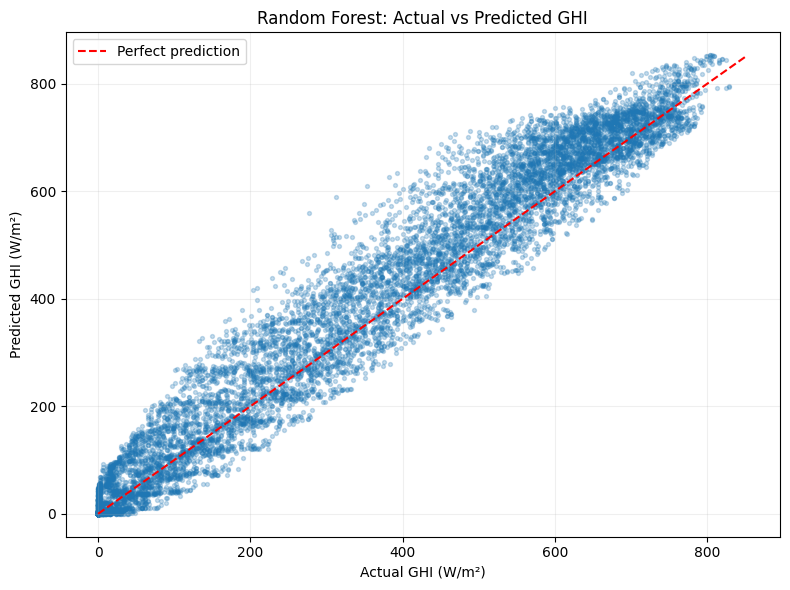

In [42]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, pred, alpha=0.25, s=8)

# Perfect prediction reference line
limit = max(y_test.max(), pred.max())
plt.plot([0, limit], [0, limit], "r--", label="Perfect prediction")

plt.xlabel("Actual GHI (W/m²)")
plt.ylabel("Predicted GHI (W/m²)")
plt.title("Random Forest: Actual vs Predicted GHI")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [43]:

# Positive error = overprediction; negative = underprediction
check = pd.DataFrame({
    "actual_ghi": y_test,
    "predicted_ghi": pred
})

check["error"] = check["predicted_ghi"] - check["actual_ghi"]

check["irradiance_band"] = pd.cut(
    check["actual_ghi"],
    bins=[-1, 50, 200, 400, 600, float("inf")],
    labels=["0–50", "50–200", "200–400", "400–600", "600+"]
)

print(
    check.groupby("irradiance_band", observed=True)
    .agg(
        mean_error=("error", "mean"),
        MAE=("error", lambda x: x.abs().mean()),
        observations=("error", "size")
    )
    .round(2)
)


                 mean_error    MAE  observations
irradiance_band                                 
0–50                   1.96   2.72         12486
50–200                26.50  49.21          1721
200–400               35.86  60.52          1993
400–600               48.38  66.03          2486
600+                  23.10  40.39          2282


In [44]:

# Sort each city's observations chronologically
forecast_df = ml_df.sort_values(
    ["location", "period_end_ist"]
).copy()

g = forecast_df.groupby("location")

# Target: GHI four 15-minute intervals into the future
forecast_df["target_ghi"] = g["ghi"].shift(-4)
forecast_df["target_time"] = g["period_end_ist"].shift(-4)

# Historical GHI features (available at prediction time)
forecast_df["ghi_now"] = forecast_df["ghi"]
forecast_df["ghi_15min_ago"] = g["ghi"].shift(1)
forecast_df["ghi_1hr_ago"] = g["ghi"].shift(4)

# Weather features measured at the current time
forecast_features = [
    "air_temp",
    "cloud_opacity",
    "relative_humidity",
    "wind_speed_10m",
    "ghi_now",
    "ghi_15min_ago",
    "ghi_1hr_ago",
    "hour_sin",
    "hour_cos",
    "year_sin",
    "year_cos",
    "location"
]

forecast_df = forecast_df.dropna(
    subset=forecast_features + ["target_ghi", "target_time"]
)

Xf = pd.get_dummies(
    forecast_df[forecast_features],
    columns=["location"],
    dtype=int
)

yf = forecast_df["target_ghi"]
target_times = forecast_df["target_time"]

print("Forecasting features:", Xf.shape)
print("Forecasting target:", yf.shape)


Forecasting features: (104808, 14)
Forecasting target: (104808,)


In [45]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

cutoff_f = target_times.quantile(0.80)

train_f = target_times < cutoff_f
test_f = target_times >= cutoff_f

Xf_train, Xf_test = Xf.loc[train_f], Xf.loc[test_f]
yf_train, yf_test = yf.loc[train_f], yf.loc[test_f]

forecast_baseline = DummyRegressor(strategy="mean")
forecast_baseline.fit(Xf_train, yf_train)
baseline_f_pred = forecast_baseline.predict(Xf_test)

forecast_model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

forecast_model.fit(Xf_train, yf_train)
forecast_pred = forecast_model.predict(Xf_test)

forecast_results = pd.DataFrame([
    evaluate("Mean baseline", yf_test, baseline_f_pred),
    evaluate("1-hour forecast", yf_test, forecast_pred)
])

print("Forecast test begins at:", cutoff_f)
print(forecast_results)


Forecast test begins at: 2025-10-19 06:09:00+05:30
             Model     MAE    RMSE     R2
0    Mean baseline  228.42  252.04 -0.028
1  1-hour forecast   11.12   25.57  0.989


In [46]:

# Persistence baseline: future GHI = current GHI
persistence_pred = Xf_test["ghi_now"].to_numpy()

comparison = pd.DataFrame([
    evaluate("Persistence (1 hour)", yf_test, persistence_pred),
    evaluate("Random Forest (1 hour)", yf_test, forecast_pred)
])

print(comparison.to_string(index=False))


                 Model   MAE  RMSE    R2
  Persistence (1 hour) 56.34 92.50 0.862
Random Forest (1 hour) 11.12 25.57 0.989


In [50]:

# City-wise performance on the same held-out test rows

test_details = forecast_df.loc[
    Xf_test.index, ["location", "target_time"]
].copy()

test_details["actual_ghi"] = yf_test
test_details["predicted_ghi"] = forecast_pred
test_details["persistence_ghi"] = persistence_pred

city_results = []

for city, group in test_details.groupby("location"):
    city_results.append({
        "Location": city,
        "RF_MAE": mean_absolute_error(
            group["actual_ghi"], group["predicted_ghi"]
        ),
        "RF_RMSE": np.sqrt(mean_squared_error(
            group["actual_ghi"], group["predicted_ghi"]
        )),
        "Persistence_MAE": mean_absolute_error(
            group["actual_ghi"], group["persistence_ghi"]
        ),
        "Observations": len(group)
    })

print(pd.DataFrame(city_results).round(2).to_string(index=False))


 Location  RF_MAE  RF_RMSE  Persistence_MAE  Observations
    Delhi   13.77    29.05            50.77          6986
Jaisalmer    8.30    19.40            60.12          6990
   Raipur   11.30    27.22            58.14          6986


In [49]:


target_hour = (
    forecast_df["target_time"].dt.hour
    + forecast_df["target_time"].dt.minute / 60
)
target_day = forecast_df["target_time"].dt.dayofyear

forecast_df.loc[:, "target_hour_sin"] = np.sin(
    2 * np.pi * target_hour / 24
)
forecast_df.loc[:, "target_hour_cos"] = np.cos(
    2 * np.pi * target_hour / 24
)
forecast_df.loc[:, "target_year_sin"] = np.sin(
    2 * np.pi * target_day / 365.25
)
forecast_df.loc[:, "target_year_cos"] = np.cos(
    2 * np.pi * target_day / 365.25
)


In [51]:

forecast_features = [
    "air_temp",
    "cloud_opacity",
    "relative_humidity",
    "wind_speed_10m",
    "ghi_now",
    "ghi_15min_ago",
    "ghi_1hr_ago",
    "target_hour_sin",
    "target_hour_cos",
    "target_year_sin",
    "target_year_cos",
    "location"
]

Xf = pd.get_dummies(
    forecast_df[forecast_features],
    columns=["location"],
    dtype=int
)

yf = forecast_df["target_ghi"]
target_times = forecast_df["target_time"]

print("Features:", Xf.shape)
print("Target:", yf.shape)
print("Missing feature values:", Xf.isna().sum().sum())


Features: (104808, 14)
Target: (104808,)
Missing feature values: 0


In [52]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor

# Split based on the target timestamp
cutoff_f = target_times.quantile(0.80)

train_f = target_times < cutoff_f
test_f = target_times >= cutoff_f

Xf_train, Xf_test = Xf.loc[train_f], Xf.loc[test_f]
yf_train, yf_test = yf.loc[train_f], yf.loc[test_f]

# Train the forecasting model
forecast_model = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

forecast_model.fit(Xf_train, yf_train)
forecast_pred = forecast_model.predict(Xf_test)

# Baselines
baseline = DummyRegressor(strategy="mean")
baseline.fit(Xf_train, yf_train)
baseline_pred = baseline.predict(Xf_test)

persistence_pred = Xf_test["ghi_now"].to_numpy()

# Compare
comparison = pd.DataFrame([
    evaluate("Mean baseline", yf_test, baseline_pred),
    evaluate("Persistence", yf_test, persistence_pred),
    evaluate("Random Forest", yf_test, forecast_pred)
])

print("Test cutoff:", cutoff_f)
print(comparison.to_string(index=False))


Test cutoff: 2025-10-19 06:09:00+05:30
        Model    MAE   RMSE     R2
Mean baseline 228.42 252.04 -0.028
  Persistence  56.34  92.50  0.862
Random Forest  10.60  25.00  0.990


In [53]:

# Build a table of actual and predicted GHI
test_details = forecast_df.loc[
    Xf_test.index,
    ["location", "target_time"]
].copy()

test_details["actual_ghi"] = yf_test
test_details["predicted_ghi"] = forecast_pred
test_details["persistence_ghi"] = persistence_pred

test_details["forecast_error"] = (
    test_details["predicted_ghi"] - test_details["actual_ghi"]
)

test_details["absolute_error"] = (
    test_details["forecast_error"].abs()
)

test_details = test_details.sort_values(
    ["location", "target_time"]
)

print(test_details.head())
print("\nPrediction rows:", len(test_details))


      location               target_time  actual_ghi  predicted_ghi  \
27954    Delhi 2025-10-19 06:15:00+05:30         0.0       0.345091   
27955    Delhi 2025-10-19 06:30:00+05:30         0.0       0.519285   
27956    Delhi 2025-10-19 06:45:00+05:30        13.0       6.321584   
27957    Delhi 2025-10-19 07:00:00+05:30        39.0      17.463337   
27958    Delhi 2025-10-19 07:15:00+05:30        72.0      47.961562   

       persistence_ghi  forecast_error  absolute_error  
27954                0        0.345091        0.345091  
27955                0        0.519285        0.519285  
27956                0       -6.678416        6.678416  
27957                0      -21.536663       21.536663  
27958                0      -24.038438       24.038438  

Prediction rows: 20962


In [54]:

import joblib
import json
import os

os.makedirs("solar_dap_artifacts", exist_ok=True)

# Save the trained forecasting model
joblib.dump(
    forecast_model,
    "solar_dap_artifacts/forecast_model.joblib"
)

# Save predictions and evaluation metrics
test_details.to_csv(
    "solar_dap_artifacts/forecast_predictions.csv",
    index=False
)

metrics = comparison.copy()
metrics.to_csv(
    "solar_dap_artifacts/model_metrics.csv",
    index=False
)

# Save model configuration and evaluation metadata
metadata = {
    "model_type": "RandomForestRegressor",
    "forecast_horizon_minutes": 60,
    "sampling_interval_minutes": 15,
    "target": "ghi",
    "features": Xf.columns.tolist(),
    "test_start": str(test_details["target_time"].min()),
    "test_end": str(test_details["target_time"].max()),
    "n_estimators": 100,
    "min_samples_leaf": 3,
    "random_state": 42
}

with open(
    "solar_dap_artifacts/forecast_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=2)

print("Saved files:")
print(os.listdir("solar_dap_artifacts"))


Saved files:
['forecast_metadata.json', 'forecast_model.joblib', 'forecast_predictions.csv', 'model_metrics.csv']


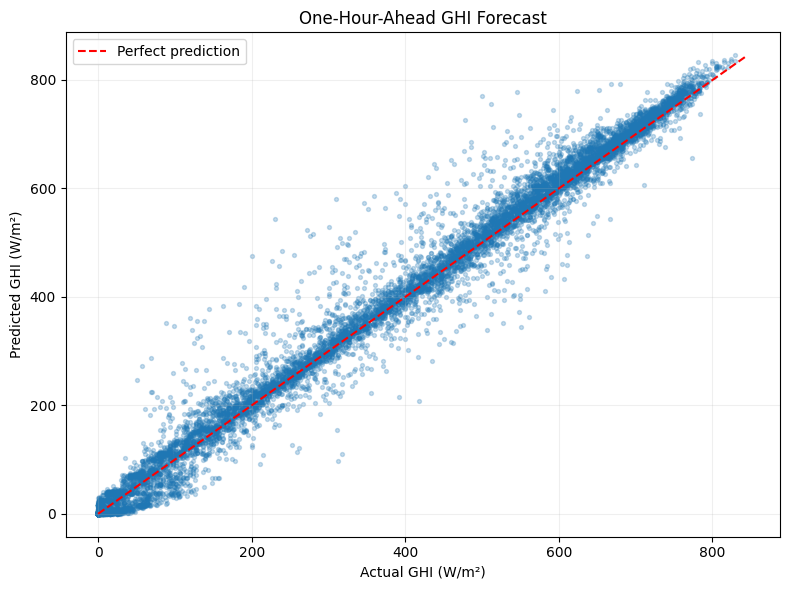

In [55]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(
    test_details["actual_ghi"],
    test_details["predicted_ghi"],
    alpha=0.25,
    s=8
)

upper = max(
    test_details["actual_ghi"].max(),
    test_details["predicted_ghi"].max()
)

plt.plot([0, upper], [0, upper], "r--", label="Perfect prediction")
plt.xlabel("Actual GHI (W/m²)")
plt.ylabel("Predicted GHI (W/m²)")
plt.title("One-Hour-Ahead GHI Forecast")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "solar_dap_artifacts/forecast_actual_vs_predicted.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()


In [57]:

anomaly_df = test_details.copy()

# Actual minus predicted GHI
anomaly_df["residual"] = (
    anomaly_df["actual_ghi"] -
    anomaly_df["predicted_ghi"]
)

anomaly_df["abs_residual"] = anomaly_df["residual"].abs()

# City-specific 99th percentile thresholds
thresholds = anomaly_df.groupby("location")[
    "abs_residual"
].quantile(0.99)

anomaly_df["threshold"] = anomaly_df["location"].map(
    thresholds
)

anomaly_df["is_anomaly"] = (
    anomaly_df["abs_residual"] > anomaly_df["threshold"]
)

print("Thresholds by city (W/m²):")
print(thresholds.round(2))

print("\nFlags by city:")
print(
    anomaly_df.groupby("location").agg(
        observations=("is_anomaly", "size"),
        flagged=("is_anomaly", "sum"),
        mean_abs_error=("abs_residual", "mean")
    ).round(2)
)

print(
    "\nTotal flagged:",
    int(anomaly_df["is_anomaly"].sum())
)


Thresholds by city (W/m²):
location
Delhi        120.72
Jaisalmer     81.46
Raipur       136.32
Name: abs_residual, dtype: float64

Flags by city:
           observations  flagged  mean_abs_error
location                                        
Delhi              6986       70           12.75
Jaisalmer          6990       70            7.93
Raipur             6986       70           11.11

Total flagged: 210


In [58]:

import os

os.makedirs("solar_dap_artifacts", exist_ok=True)

# Export all scored observations, not just flagged ones
anomaly_df.to_csv(
    "solar_dap_artifacts/anomaly_results.csv",
    index=False
)

# Export a compact table containing only flagged observations
flagged_df = (
    anomaly_df[anomaly_df["is_anomaly"]]
    .sort_values("abs_residual", ascending=False)
    .copy()
)

flagged_df.to_csv(
    "solar_dap_artifacts/flagged_anomalies.csv",
    index=False
)

print("Saved anomaly files.")
print("All scored observations:", len(anomaly_df))
print("Flagged observations:", len(flagged_df))
print("\nLargest forecast errors:")
print(
    flagged_df[
        ["location", "target_time", "actual_ghi",
         "predicted_ghi", "residual", "threshold"]
    ].head(10).to_string(index=False)
)


Saved anomaly files.
All scored observations: 20962
Flagged observations: 210

Largest forecast errors:
 location               target_time  actual_ghi  predicted_ghi    residual  threshold
Jaisalmer 2025-12-28 14:30:00+05:30       230.0     543.018411 -313.018411  81.456728
    Delhi 2025-10-30 12:00:00+05:30       200.0     475.417294 -275.417294 120.720369
   Raipur 2025-12-22 13:45:00+05:30       310.0     581.353469 -271.353469 136.322257
   Raipur 2025-11-07 12:45:00+05:30       500.0     771.138044 -271.138044 136.322257
    Delhi 2025-10-30 14:45:00+05:30        89.0     351.724683 -262.724683 120.720369
    Delhi 2025-10-27 13:15:00+05:30       272.0     523.507391 -251.507391 120.720369
Jaisalmer 2025-12-06 13:00:00+05:30       478.0     726.165404 -248.165404  81.456728
    Delhi 2025-10-30 13:15:00+05:30        99.0     345.827296 -246.827296 120.720369
    Delhi 2025-10-30 11:30:00+05:30       240.0     484.470889 -244.470889 120.720369
   Raipur 2025-11-07 13:00:00+05:30 

In [59]:

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("solar_dap_artifacts", exist_ok=True)

city_rows = []

for city, group in test_details.groupby("location"):
    actual = group["actual_ghi"]
    rf_pred = group["predicted_ghi"]
    persistence = group["persistence_ghi"]

    city_rows.append({
        "location": city,
        "observations": len(group),
        "RF_MAE": mean_absolute_error(actual, rf_pred),
        "RF_RMSE": np.sqrt(mean_squared_error(actual, rf_pred)),
        "RF_R2": r2_score(actual, rf_pred),
        "Persistence_MAE": mean_absolute_error(
            actual, persistence
        ),
        "Persistence_RMSE": np.sqrt(
            mean_squared_error(actual, persistence)
        ),
        "Persistence_R2": r2_score(actual, persistence)
    })

city_metrics = pd.DataFrame(city_rows).round(3)

city_metrics.to_csv(
    "solar_dap_artifacts/city_wise_metrics.csv",
    index=False
)

print(city_metrics.to_string(index=False))


 location  observations  RF_MAE  RF_RMSE  RF_R2  Persistence_MAE  Persistence_RMSE  Persistence_R2
    Delhi          6986  12.749   27.824  0.984           50.766            84.276           0.854
Jaisalmer          6990   7.932   18.958  0.995           60.120            98.130           0.864
   Raipur          6986  11.106   27.240  0.989           58.137            94.539           0.863


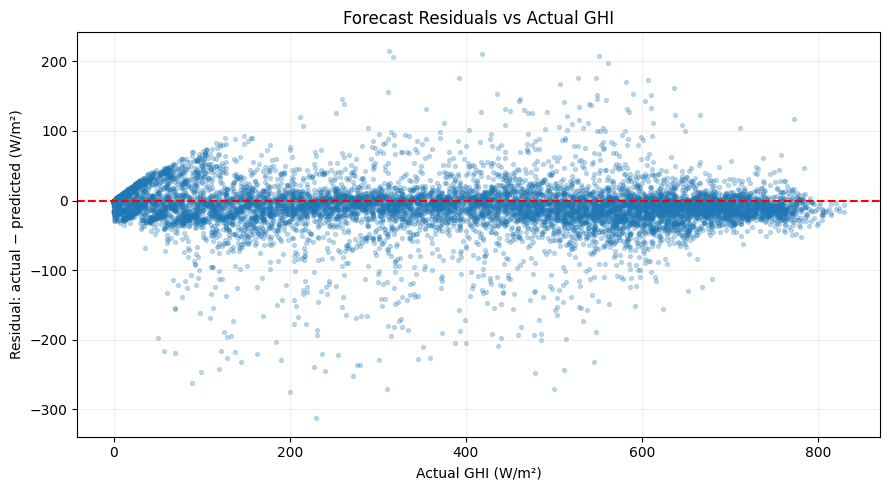

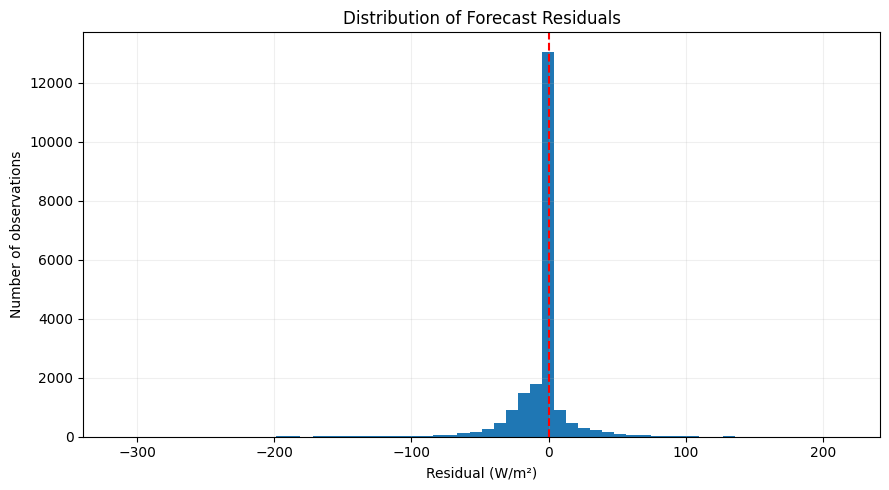

Residual mean: -4.554
Residual median: 0.0
Residual standard deviation: 24.586


In [60]:

# Recalculate residuals to ensure consistency
residual_df = test_details.copy()

residual_df["residual"] = (
    residual_df["actual_ghi"]
    - residual_df["predicted_ghi"]
)

residual_df["abs_residual"] = residual_df["residual"].abs()

# Plot 1: residuals against actual GHI
plt.figure(figsize=(9, 5))
plt.scatter(
    residual_df["actual_ghi"],
    residual_df["residual"],
    alpha=0.25,
    s=8
)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Actual GHI (W/m²)")
plt.ylabel("Residual: actual − predicted (W/m²)")
plt.title("Forecast Residuals vs Actual GHI")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    "solar_dap_artifacts/residuals_vs_actual.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# Plot 2: distribution of residuals
plt.figure(figsize=(9, 5))
plt.hist(residual_df["residual"], bins=60)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Residual (W/m²)")
plt.ylabel("Number of observations")
plt.title("Distribution of Forecast Residuals")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(
    "solar_dap_artifacts/residual_distribution.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

print("Residual mean:", round(residual_df["residual"].mean(), 3))
print("Residual median:", round(residual_df["residual"].median(), 3))
print("Residual standard deviation:", round(residual_df["residual"].std(), 3))


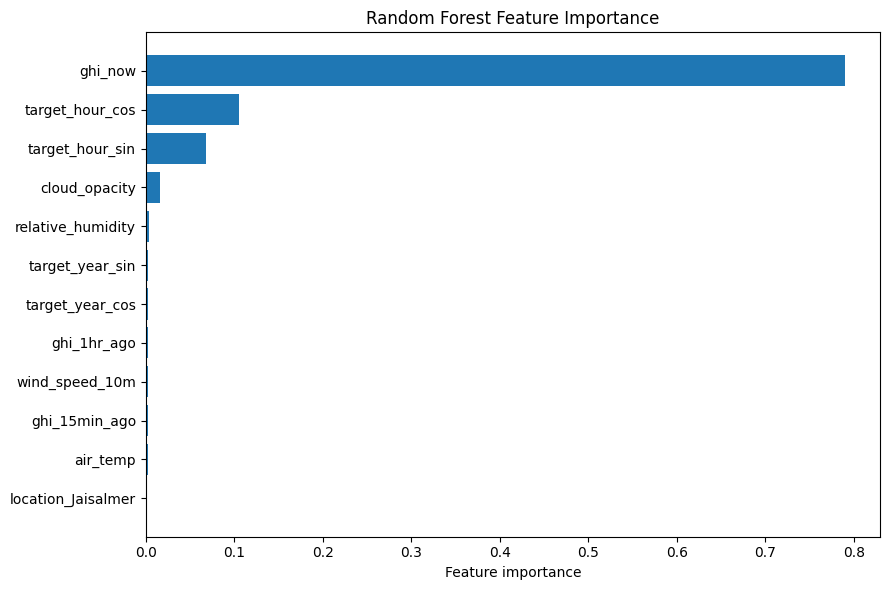

Metadata and feature importance saved.

Top features:
          feature  importance
          ghi_now    0.790260
  target_hour_cos    0.105754
  target_hour_sin    0.067730
    cloud_opacity    0.016059
relative_humidity    0.003522
  target_year_sin    0.002888
  target_year_cos    0.002675
      ghi_1hr_ago    0.002665
   wind_speed_10m    0.002627
    ghi_15min_ago    0.002357


In [61]:

# Save feature importance
importance = pd.DataFrame({
    "feature": Xf_train.columns,
    "importance": forecast_model.feature_importances_
}).sort_values("importance", ascending=False)

importance.to_csv(
    "solar_dap_artifacts/feature_importance.csv",
    index=False
)

# Plot feature importance
plt.figure(figsize=(9, 6))
top_features = importance.head(12).sort_values("importance")

plt.barh(
    top_features["feature"],
    top_features["importance"]
)
plt.xlabel("Feature importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.savefig(
    "solar_dap_artifacts/feature_importance.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()

# Record evaluation metadata
metadata = {
    "project": "SOLAR DAP",
    "model_type": "RandomForestRegressor",
    "target": "ghi",
    "forecast_horizon_minutes": 60,
    "sampling_interval_minutes": 15,
    "features": Xf.columns.tolist(),
    "training_rows": int(len(Xf_train)),
    "test_rows": int(len(Xf_test)),
    "test_start": str(test_details["target_time"].min()),
    "test_end": str(test_details["target_time"].max()),
    "test_split_method": "Chronological by target timestamp",
    "n_estimators": 100,
    "min_samples_leaf": 3,
    "random_state": 42,
    "anomaly_method": "City-specific 99th percentile of absolute residuals",
    "anomaly_thresholds_w_m2": {
        str(k): float(v)
        for k, v in thresholds.items()
    },
    "limitations": [
        "Metrics are from a single chronological holdout period.",
        "Anomaly thresholds were explored on test residuals and require separate calibration before deployment.",
        "The inference pipeline must reproduce the saved feature engineering and encoding."
    ]
}

with open(
    "solar_dap_artifacts/model_metadata.json",
    "w"
) as f:
    json.dump(metadata, f, indent=2)

print("Metadata and feature importance saved.")
print("\nTop features:")
print(importance.head(10).to_string(index=False))


In [62]:

print("SOLAR DAP ML artifacts:\n")

for filename in sorted(os.listdir("solar_dap_artifacts")):
    path = os.path.join("solar_dap_artifacts", filename)
    print(f"{filename:40} {os.path.getsize(path):>10,} bytes")


SOLAR DAP ML artifacts:

anomaly_results.csv                       2,548,277 bytes
city_wise_metrics.csv                           245 bytes
feature_importance.csv                          521 bytes
feature_importance.png                       61,567 bytes
flagged_anomalies.csv                        33,918 bytes
forecast_actual_vs_predicted.png            253,626 bytes
forecast_metadata.json                          611 bytes
forecast_model.joblib                    111,316,641 bytes
forecast_predictions.csv                  1,560,970 bytes
model_metadata.json                           1,243 bytes
model_metrics.csv                               111 bytes
residual_distribution.png                    43,778 bytes
residuals_vs_actual.png                     279,209 bytes


In [63]:

import shutil

zip_path = shutil.make_archive(
    "solar_dap_ml_v1",
    "zip",
    root_dir=".",
    base_dir="solar_dap_artifacts"
)

print("Created:", zip_path)


Created: /content/solar_dap_ml_v1.zip


In [64]:

from google.colab import files
files.download("solar_dap_ml_v1.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>